<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/gauge_theory/gauge_ch08_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gauge Theory* — `gauge_ch08_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Gauge Theory Ch 8 Figures — Colab Notebook
**Gauge Theory · Chapter 8: QFT in Three Dimensions**

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §8.2   | Particle-vortex duality: phase diagrams, duality map |
| fig02  | §8.4   | Chern-Simons: level quantisation, GSD on $T^2$, anyon statistics |
| fig03  | §8.6   | Duality web: core duality, web connections, FQH states |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Rectangle
from matplotlib.lines import Line2D
import os

BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
AMBER  = '#e8a838'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMBER, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

OUTDIR = 'figures/ch08'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')

Setup complete.


---
## fig01 · Particle-Vortex Duality (§8.2)

**Left**: XY model phase diagram (superfluid vs Mott insulator)  
**Middle**: Abelian-Higgs phase diagram (Higgs vs Coulomb)  
**Right**: Duality map — particles ↔ vortices, phases ↔ phases

  saved -> figures/ch08/fig01_pvduality.png


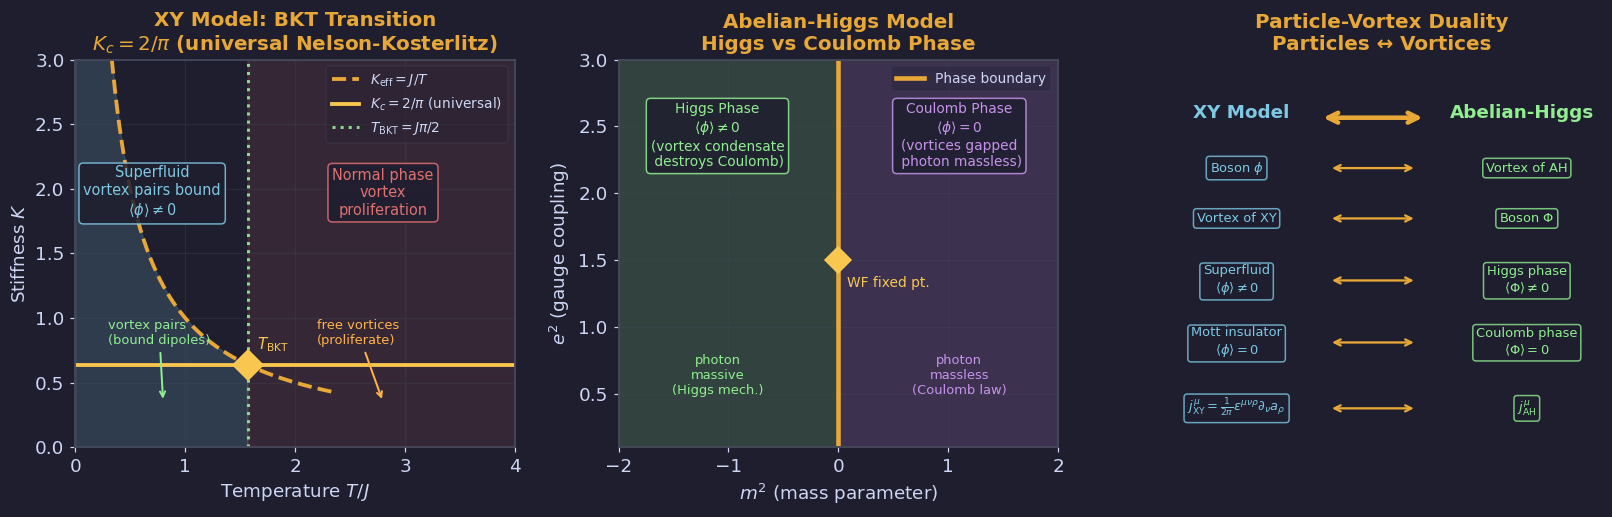

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: XY model BKT phase diagram (CORRECTED) ─────────────────────────
# Physical BKT: transition at K_c = 2/pi (Nelson-Kosterlitz universal value).
# For simple XY (coupling J): K_eff(T) = J/T; transition where K_eff = K_c → T_BKT = J*pi/2
ax = axes[0]
ax.set_facecolor(BG)

J = 1.0; K_c = 2.0/np.pi; T_BKT = J*np.pi/2
T_arr = np.linspace(0, 4, 400)
K_eff = np.minimum(J / np.maximum(T_arr, 0.01), 5)

ax.fill_between(T_arr, 0, np.minimum(K_eff, 3),
                where=T_arr < T_BKT, color=BLUE, alpha=0.18)
ax.fill_between(T_arr, 0, 3,
                where=T_arr >= T_BKT, color=RED, alpha=0.12)
ax.plot(T_arr[T_arr < T_BKT*1.5], K_eff[T_arr < T_BKT*1.5],
        color=AMBER, lw=2.5, ls='--', label=r'$K_{\rm eff}=J/T$')
ax.axhline(K_c, color=YELLOW, lw=2.5, label=r'$K_c=2/\pi$ (universal)')
ax.axvline(T_BKT, color=GREEN, lw=2, ls=':', alpha=0.9, label=r'$T_{\rm BKT}=J\pi/2$')
ax.plot(T_BKT, K_c, 'D', color=YELLOW, ms=14, zorder=5)
ax.text(T_BKT+0.08, K_c+0.12, r'$T_{\rm BKT}$', fontsize=10, color=YELLOW)

ax.text(0.7, 1.8, 'Superfluid\nvortex pairs bound\n'+r'$\langle\phi\rangle\neq 0$',
        ha='center', fontsize=9.5, color=BLUE,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=BLUE, alpha=0.85))
ax.text(2.8, 1.8, 'Normal phase\nvortex\nproliferation',
        ha='center', fontsize=9.5, color=RED,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=RED, alpha=0.85))
ax.annotate('vortex pairs\n(bound dipoles)', xy=(0.8,0.35), xytext=(0.3,0.8),
            fontsize=8.5, color=GREEN,
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.3))
ax.annotate('free vortices\n(proliferate)', xy=(2.8,0.35), xytext=(2.2,0.8),
            fontsize=8.5, color=ORANGE,
            arrowprops=dict(arrowstyle='->', color=ORANGE, lw=1.3))

ax.set_xlabel('Temperature $T/J$'); ax.set_ylabel(r'Stiffness $K$')
ax.set_title('XY Model: BKT Transition\n'+r'$K_c=2/\pi$ (universal Nelson-Kosterlitz)')
ax.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax.set_xlim(0, 4); ax.set_ylim(0, 3); ax.grid(True, alpha=0.3)

# ── Middle: Abelian-Higgs phase diagram (CORRECTED labels) ───────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

e2_arr = np.linspace(0.1, 3, 300)
ax2.axvline(0, color=AMBER, lw=3, label='Phase boundary')
ax2.fill_betweenx(e2_arr, -2, 0, color=GREEN, alpha=0.18)
ax2.fill_betweenx(e2_arr, 0, 2, color=PURPLE, alpha=0.18)

# CORRECTED: Higgs phase = vortex condensate (not "vortex condensate forms" on wrong side)
ax2.text(-1.1, 2.2, 'Higgs Phase\n'+r'$\langle\phi\rangle\neq 0$'+
         '\n(vortex condensate\n destroys Coulomb)',
         ha='center', fontsize=9, color=GREEN,
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=GREEN, alpha=0.85))
ax2.text(1.1, 2.2, 'Coulomb Phase\n'+r'$\langle\phi\rangle=0$'+
         '\n(vortices gapped\n photon massless)',
         ha='center', fontsize=9, color=PURPLE,
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=PURPLE, alpha=0.85))
ax2.text(-1.1, 0.5, 'photon\nmassive\n(Higgs mech.)', ha='center', fontsize=8.5, color=GREEN)
ax2.text(1.1, 0.5, 'photon\nmassless\n(Coulomb law)', ha='center', fontsize=8.5, color=PURPLE)

ax2.plot(0, 1.5, 'D', color=YELLOW, ms=12, zorder=5)
ax2.text(0.08, 1.3, 'WF fixed pt.', fontsize=9, color=YELLOW)

ax2.set_xlabel(r'$m^2$ (mass parameter)'); ax2.set_ylabel(r'$e^2$ (gauge coupling)')
ax2.set_title('Abelian-Higgs Model\nHiggs vs Coulomb Phase')
ax2.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax2.set_xlim(-2, 2); ax2.set_ylim(0.1, 3); ax2.grid(True, alpha=0.3)

# ── Right: Duality table (no arrow overlap) ───────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG); ax3.axis('off')

ax3.text(0.18, 0.85, 'XY Model', ha='center', fontsize=12,
         color=BLUE, fontweight='bold', transform=ax3.transAxes)
ax3.text(0.82, 0.85, 'Abelian-Higgs', ha='center', fontsize=12,
         color=GREEN, fontweight='bold', transform=ax3.transAxes)
ax3.annotate('', xy=(0.60, 0.85), xytext=(0.36, 0.85),
             arrowprops=dict(arrowstyle='<->', color=AMBER, lw=3, mutation_scale=16),
             xycoords='axes fraction', textcoords='axes fraction')
# ax3.text(0.48, 0.85, 'Particle-Vortex\nDuality', ha='center', fontsize=9.5,
#          color=AMBER, fontweight='bold', transform=ax3.transAxes)

rows = [
    ('Boson $\\phi$',                r'Vortex of AH',                       0.72),
    ('Vortex of XY',                 'Boson $\\Phi$',                        0.59),
    ('Superfluid\n'+r'$\langle\phi\rangle\neq 0$',
     'Higgs phase\n'+r'$\langle\Phi\rangle\neq 0$',                         0.43),
    ('Mott insulator\n'+r'$\langle\phi\rangle=0$',
     'Coulomb phase\n'+r'$\langle\Phi\rangle=0$',                           0.27),
    (r'$j^\mu_{\rm XY}=\frac{1}{2\pi}\varepsilon^{\mu\nu\rho}\partial_\nu a_\rho$',
     r'$j^\mu_{\rm AH}$',                                                    0.10),
]
for lhs, rhs, y in rows:
    ax3.text(0.17, y, lhs, ha='center', va='center', fontsize=8.5, color=BLUE,
             transform=ax3.transAxes,
             bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=BLUE, alpha=0.8))
    ax3.text(0.83, y, rhs, ha='center', va='center', fontsize=8.5, color=GREEN,
             transform=ax3.transAxes,
             bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=GREEN, alpha=0.8))
    ax3.annotate('', xy=(0.58, y), xytext=(0.38, y),
                arrowprops=dict(arrowstyle='<->', color=AMBER, lw=1.5, mutation_scale=10),
                xycoords='axes fraction', textcoords='axes fraction')

ax3.set_title('Particle-Vortex Duality\nParticles ↔ Vortices')

plt.tight_layout(pad=1.5)
save('fig01_pvduality.png', fig)


---
## fig02 · Chern-Simons Theory (§8.4)

**Left**: Large gauge transformation shifts CS action by $k\times$ integer  
**Middle**: Ground state degeneracy on $T^2$ = $|k|$ vs level $k$  
**Right**: Anyon statistics $\theta = \pi/k$ vs level, with FQH filling $\nu=1/k$

  saved -> figures/ch08/fig02_chern_simons.png


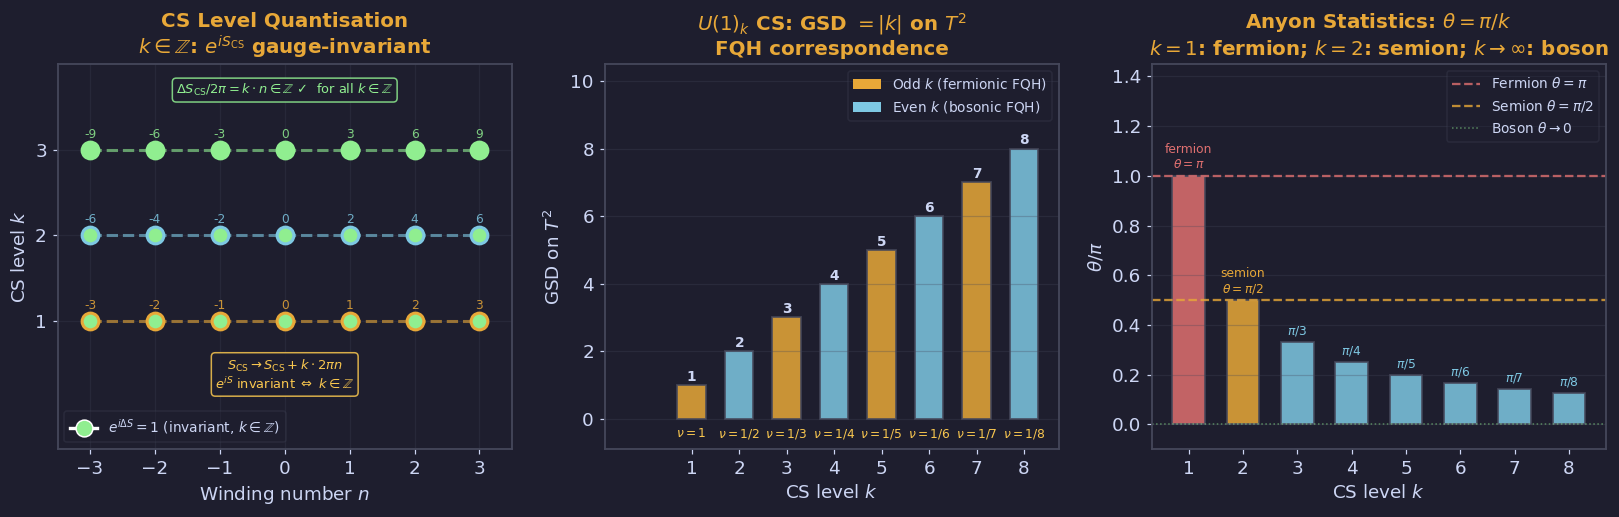

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: CS level quantisation (CORRECTED) ───────────────────────────────
# Under large gauge transformation winding n:  S_CS → S_CS + k * 2π * n
# e^{iS} invariant iff k * 2πn ∈ 2πZ for all n ∈ Z  →  k ∈ Z (always satisfied).
# All integer k are valid. Show ΔS/2π = k*n for k=1,2,3.
ax = axes[0]
ax.set_facecolor(BG)

n_wind = np.arange(-3, 4)
k_values = [1, 2, 3]; colors_k = [AMBER, BLUE, GREEN]

for k_v, col in zip(k_values, colors_k):
    ax.scatter(n_wind, k_v*np.ones_like(n_wind),
               c=GREEN, s=120, zorder=5, edgecolors=col, linewidths=2)
    ax.plot(n_wind, k_v*np.ones_like(n_wind),
            color=col, lw=2, ls='--', alpha=0.6, label=f'$k={k_v}$')
    for n in n_wind:
        ax.text(n, k_v+0.14, f'{k_v*n}', ha='center', fontsize=8, color=col, alpha=0.85)

ax.text(0, 3.65,
        r'$\Delta S_{\rm CS}/2\pi = k\cdot n\in\mathbb{Z}$ ✓  for all $k\in\mathbb{Z}$',
        ha='center', fontsize=8.5, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=GREEN, alpha=0.85))
ax.text(0, 0.2,
        r'$S_{\rm CS}\to S_{\rm CS}+k\cdot 2\pi n$' + chr(10) +
        r'$e^{iS}$ invariant $\Leftrightarrow$ $k\in\mathbb{Z}$',
        ha='center', fontsize=8.5, color=YELLOW,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELLOW, alpha=0.85))

from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0],[0], marker='o', color='w', markerfacecolor=GREEN, ms=11,
           label=r'$e^{i\Delta S}=1$ (invariant, $k\in\mathbb{Z}$)'),
], fontsize=9, labelcolor=FG)
ax.set_xlabel(r'Winding number $n$'); ax.set_ylabel(r'CS level $k$')
ax.set_title('CS Level Quantisation\n'+
             r'$k\in\mathbb{Z}$: $e^{iS_{\rm CS}}$ gauge-invariant')
ax.set_xticks(n_wind); ax.set_yticks(k_values)
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-0.5, 4.0)
ax.grid(True, alpha=0.25)

# ── Middle: GSD on T^2 ────────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

k_range = np.arange(1, 9); GSD = k_range
bar_cols = [AMBER if k%2==1 else BLUE for k in k_range]
bars = ax2.bar(k_range, GSD, color=bar_cols, edgecolor=EDGE, lw=1.2, alpha=0.85, width=0.6)

for bar, gsd in zip(bars, GSD):
    ax2.text(bar.get_x()+bar.get_width()/2, gsd+0.12,
             str(gsd), ha='center', fontsize=9, color=FG, fontweight='bold')

fqh_labels = [r'$\nu=1$', r'$\nu=1/2$', r'$\nu=1/3$', r'$\nu=1/4$',
               r'$\nu=1/5$', r'$\nu=1/6$', r'$\nu=1/7$', r'$\nu=1/8$']
for k, lbl in zip(k_range, fqh_labels):
    ax2.text(k, -0.55, lbl, ha='center', fontsize=8, color=YELLOW)

ax2.set_xlabel(r'CS level $k$'); ax2.set_ylabel(r'GSD on $T^2$')
ax2.set_title(r'$U(1)_k$ CS: GSD $=|k|$ on $T^2$' + '\nFQH correspondence')
ax2.set_xticks(k_range); ax2.set_ylim(-0.9, 10.5)
ax2.bar(0,0, color=AMBER, label='Odd $k$ (fermionic FQH)')
ax2.bar(0,0, color=BLUE,  label='Even $k$ (bosonic FQH)')
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True, axis='y', alpha=0.3)

# ── Right: Anyon statistics (CORRECTED: k=1 → fermion, not boson) ────────
ax3 = axes[2]
ax3.set_facecolor(BG)

k_arr = np.arange(1, 9)
# CORRECT: theta = pi/k
# k=1: theta=pi (FERMION — not boson!)
# k=2: theta=pi/2 (semion)
# k→∞: theta→0 (approaches boson)
theta_norm = 1.0/k_arr   # theta/pi = 1/k

bar_cols3 = [RED if k==1 else (AMBER if k==2 else BLUE) for k in k_arr]
ax3.bar(k_arr, theta_norm, color=bar_cols3, edgecolor=EDGE, lw=1.2, alpha=0.85, width=0.6)

stats_names = ['fermion\n'+r'$\theta=\pi$', 'semion\n'+r'$\theta=\pi/2$',
               r'$\pi/3$', r'$\pi/4$', r'$\pi/5$', r'$\pi/6$', r'$\pi/7$', r'$\pi/8$']
stat_cols   = [RED, AMBER] + [BLUE]*6
for k, tn, name, col in zip(k_arr, theta_norm, stats_names, stat_cols):
    ax3.text(k, tn+0.03, name, ha='center', fontsize=8, color=col)

ax3.axhline(1.0, color=RED,   lw=1.5, ls='--', alpha=0.8, label=r'Fermion $\theta=\pi$')
ax3.axhline(0.5, color=AMBER, lw=1.5, ls='--', alpha=0.8, label=r'Semion $\theta=\pi/2$')
ax3.axhline(0.0, color=GREEN, lw=1.0, ls=':',  alpha=0.5, label=r'Boson $\theta\to 0$')

ax3.set_xlabel(r'CS level $k$'); ax3.set_ylabel(r'$\theta/\pi$')
ax3.set_title(r'Anyon Statistics: $\theta=\pi/k$' + '\n' +
              r'$k=1$: fermion; $k=2$: semion; $k\to\infty$: boson')
ax3.set_xticks(k_arr); ax3.set_ylim(-0.1, 1.45)
ax3.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax3.grid(True, axis='y', alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig02_chern_simons.png', fig)


---
## fig03 · 3D Duality Web (§8.6)

**Left**: Core duality schematic — free boson ↔ free fermion + CS  
**Middle**: Duality web — network of connected theories  
**Right**: FQH hierarchy from CS dualities, Hall conductance ladder

  saved -> figures/ch08/fig03_duality_web.png


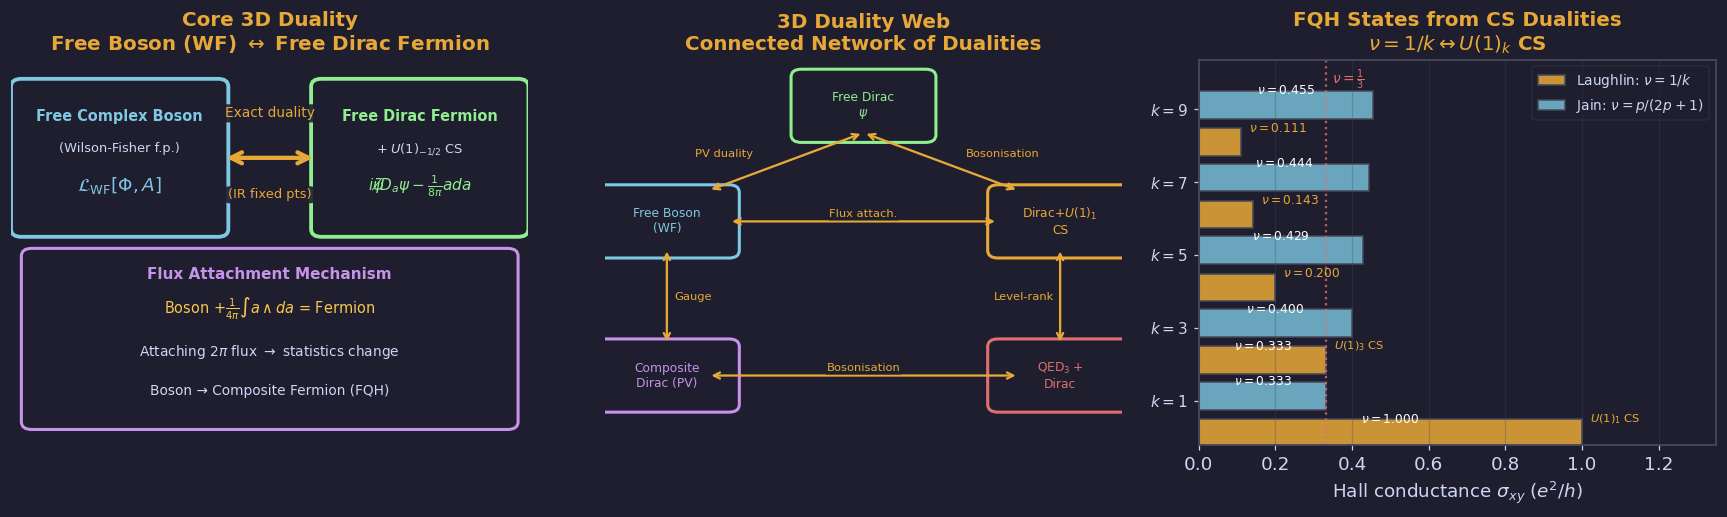

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor(BG)

# ── Panel 1: Core duality ─────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')

ax.add_patch(FancyBboxPatch((0.02,0.56),0.38,0.37,
    boxstyle='round,pad=0.02',fc=BG,ec=BLUE,lw=2.5,transform=ax.transAxes))
ax.text(0.21,0.84,'Free Complex Boson',ha='center',fontsize=9.5,
        color=BLUE,fontweight='bold',transform=ax.transAxes)
ax.text(0.21,0.76,'(Wilson-Fisher f.p.)',ha='center',fontsize=8.5,
        color=FG,transform=ax.transAxes)
ax.text(0.21,0.66,r'$\mathcal{L}_{\rm WF}[\Phi,A]$',ha='center',fontsize=12,
        color=BLUE,transform=ax.transAxes)

ax.add_patch(FancyBboxPatch((0.60,0.56),0.38,0.37,
    boxstyle='round,pad=0.02',fc=BG,ec=GREEN,lw=2.5,transform=ax.transAxes))
ax.text(0.79,0.84,'Free Dirac Fermion',ha='center',fontsize=9.5,
        color=GREEN,fontweight='bold',transform=ax.transAxes)
ax.text(0.79,0.76,r'$+\;U(1)_{-1/2}$ CS',ha='center',fontsize=8.5,
        color=FG,transform=ax.transAxes)
ax.text(0.79,0.66,r'$i\bar\psi\not\!D_a\psi - \frac{1}{8\pi}ada$',
        ha='center',fontsize=10,color=GREEN,transform=ax.transAxes)

ax.annotate('',xy=(0.59,0.745),xytext=(0.41,0.745),
    arrowprops=dict(arrowstyle='<->',color=AMBER,lw=2.8,mutation_scale=18),
    xycoords='axes fraction',textcoords='axes fraction')
ax.text(0.50,0.85,'Exact duality',ha='center',fontsize=9,color=AMBER,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.15',fc=BG,ec='none',alpha=0.9))
ax.text(0.50,0.64,'(IR fixed pts)',ha='center',fontsize=8.5,color=AMBER,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.15',fc=BG,ec='none',alpha=0.9))

ax.add_patch(FancyBboxPatch((0.04,0.06),0.92,0.43,
    boxstyle='round,pad=0.02',fc=BG,ec=PURPLE,lw=2.0,transform=ax.transAxes))
ax.text(0.50,0.43,'Flux Attachment Mechanism',ha='center',fontsize=10,
        color=PURPLE,fontweight='bold',transform=ax.transAxes)
ax.text(0.50,0.34,r'Boson $+ \frac{1}{4\pi}\int a\wedge da$ = Fermion',
        ha='center',fontsize=9.5,color=YELLOW,transform=ax.transAxes)
ax.text(0.50,0.23,r'Attaching $2\pi$ flux $\to$ statistics change',
        ha='center',fontsize=9,color=FG,transform=ax.transAxes)
ax.text(0.50,0.13,'Boson → Composite Fermion (FQH)',
        ha='center',fontsize=9,color=FG,transform=ax.transAxes)
ax.set_title('Core 3D Duality\n'+r'Free Boson (WF) $\leftrightarrow$ Free Dirac Fermion')

# ── Panel 2: Duality web (FIXED edge label offsets) ──────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.axis('off')

NW, NH = 0.24, 0.15
nodes = {
    'Free Dirac\n$\\psi$':        (0.50, 0.88, GREEN),
    'Free Boson\n(WF)':           (0.12, 0.58, BLUE),
    'Dirac$+U(1)_1$\nCS':         (0.88, 0.58, AMBER),
    'Composite\nDirac (PV)':       (0.12, 0.18, PURPLE),
    'QED$_3+$\nDirac':            (0.88, 0.18, RED),
}
for name,(x,y,col) in nodes.items():
    ax2.add_patch(FancyBboxPatch((x-NW/2,y-NH/2),NW,NH,
        boxstyle='round,pad=0.02',fc=BG,ec=col,lw=2.0,transform=ax2.transAxes))
    ax2.text(x,y,name,ha='center',va='center',fontsize=8,
             color=col,transform=ax2.transAxes)

def edge(ax, x1,y1,x2,y2,lbl,lbl_dx=0,lbl_dy=0):
    ax.annotate('',xy=(x2,y2),xytext=(x1,y1),
        arrowprops=dict(arrowstyle='<->',color=AMBER,lw=1.5,mutation_scale=10),
        xycoords='axes fraction',textcoords='axes fraction')
    ax.text((x1+x2)/2+lbl_dx,(y1+y2)/2+lbl_dy,lbl,
            ha='center',va='center',fontsize=7.5,color=AMBER,
            transform=ax2.transAxes,
            bbox=dict(boxstyle='round,pad=0.15',fc=BG,ec='none',alpha=0.88))

# FIXED: horizontal edge labels pushed clear of arrows (lbl_dy=0.08 / 0.09)
edge(ax2, 0.50,0.81, 0.20,0.66, 'PV duality',   lbl_dx=-0.12, lbl_dy=0.02)
edge(ax2, 0.50,0.81, 0.80,0.66, 'Bosonisation', lbl_dx= 0.12, lbl_dy=0.02)
edge(ax2, 0.24,0.58, 0.76,0.58, 'Flux attach.', lbl_dx= 0.00, lbl_dy=0.02)
edge(ax2, 0.12,0.51, 0.12,0.26, 'Gauge',        lbl_dx= 0.05, lbl_dy=0.00)
edge(ax2, 0.88,0.51, 0.88,0.26, 'Level-rank',   lbl_dx=-0.07, lbl_dy=0.00)
edge(ax2, 0.20,0.18, 0.80,0.18, 'Bosonisation', lbl_dx= 0.00, lbl_dy=0.02)
ax2.set_title('3D Duality Web\nConnected Network of Dualities')

# ── Panel 3: FQH states (FIXED: remove erroneous yc-0.2 offset) ──────────
ax3 = axes[2]
ax3.set_facecolor(BG)

k_vals = np.array([1,3,5,7,9]); nu_L = 1.0/k_vals
p_vals = np.array([1,2,3,4,5]); nu_J = p_vals/(2.0*p_vals+1)

bar_h = 0.35; gap = 0.12
y_L = np.arange(len(k_vals), dtype=float) * (2*bar_h + gap + 0.10)
y_J = y_L + bar_h + gap

ax3.barh(y_L, nu_L, height=bar_h, color=AMBER, alpha=0.85,
         edgecolor=EDGE, lw=1.2, label=r'Laughlin: $\nu=1/k$')
ax3.barh(y_J, nu_J, height=bar_h, color=BLUE,  alpha=0.80,
         edgecolor=EDGE, lw=1.2, label=r'Jain: $\nu=p/(2p+1)$')

# FIXED: labels centred in bar (no -0.2 y-offset)
for i,(k,nu) in enumerate(zip(k_vals, nu_L)):
    yc = y_L[i] + bar_h/2
    lbl = f'$\\nu={nu:.3f}$'
    if nu > 0.26:
        ax3.text(nu/2, yc, lbl, ha='center', va='center',
                 fontsize=8, color='white', fontweight='bold')
        ax3.text(nu+0.02, yc, f'$U(1)_{{{k}}}$ CS',
                 ha='left', va='center', fontsize=7.5, color=AMBER)
    else:
        ax3.text(nu+0.02, yc, lbl, ha='left', va='center', fontsize=8, color=AMBER)

for i,(p,nu) in enumerate(zip(p_vals, nu_J)):
    yc = y_J[i] + bar_h/2
    if nu > 0.26:
        ax3.text(nu/2, yc, f'$\\nu={nu:.3f}$',
                 ha='center', va='center', fontsize=8, color='white', fontweight='bold')
    else:
        ax3.text(nu+0.02, yc, f'$\\nu={nu:.3f}$',
                 ha='left', va='center', fontsize=8, color=BLUE)

ax3.axvline(1/3, color=RED, lw=1.5, ls=':', alpha=0.8)
ax3.text(1/3 +0.1, y_J[-1]+bar_h+0.12, r'$\nu=\frac{1}{3}$',
         ha='right', va='top', fontsize=9, color=RED)

ax3.set_yticks(y_L + bar_h + gap/2)
ax3.set_yticklabels([f'$k={k}$' for k in k_vals], fontsize=10)
ax3.set_xlim(0, 1.35); ax3.set_ylim(-0.15, y_J[-1]+bar_h+0.22)
ax3.set_xlabel(r'Hall conductance $\sigma_{xy}\;(e^2/h)$')
ax3.set_title('FQH States from CS Dualities\n'+r'$\nu=1/k\leftrightarrow U(1)_k$ CS')
ax3.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax3.grid(True, axis='x', alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig03_duality_web.png', fig)


---
## Download figures

In [5]:
import shutil
from google.colab import files

shutil.make_archive('gauge_ch08_figures', 'zip', '.', 'figures')
files.download('gauge_ch08_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Checklist

| File | Content | Status |
|------|---------|--------|
| `fig01_pvduality.png`    | XY/Abelian-Higgs phase diagrams, particle-vortex duality map | ☐ |
| `fig02_chern_simons.png` | Level quantisation, GSD on $T^2$, anyon statistics | ☐ |
| `fig03_duality_web.png`  | Core duality, duality web, FQH from CS | ☐ |